# Handoffs Pattern (핸드오프 패턴을 state machine 방식으로 구현한 예제)

- 도구 호출을 사용하여 단일 에이전트의 구성을 동적으로 변경하는 상태 머신을 구현하는 방법
- 현재 상태에 따라 사용 가능한 도구와 명령어를 업데이트 → 동일한 기본 에이전트의 서로 다른 구성(시스템 프롬프트 + 도구)
- warranty_collector(보증 확인) → issue_classifier(문제 분류) → resolution_specialist(해결)
                      
### 다음과 같은 기능을 수행하는 고객 지원 상담원을 만들어 보겠습니다.
- 진행하기 전에 보증 정보를 수집합니다.
- 문제를 하드웨어 또는 소프트웨어 문제로 분류합니다.
- 문제 해결을 제공하거나 담당자에게 인계합니다.
- 여러 차례의 대화에 걸쳐 대화 상태를 유지합니다.

**참고**: [LangChain 공식 문서 - Handoffs Customer Support](https://docs.langchain.com/oss/python/langchain/multi-agent/handoffs-customer-support)

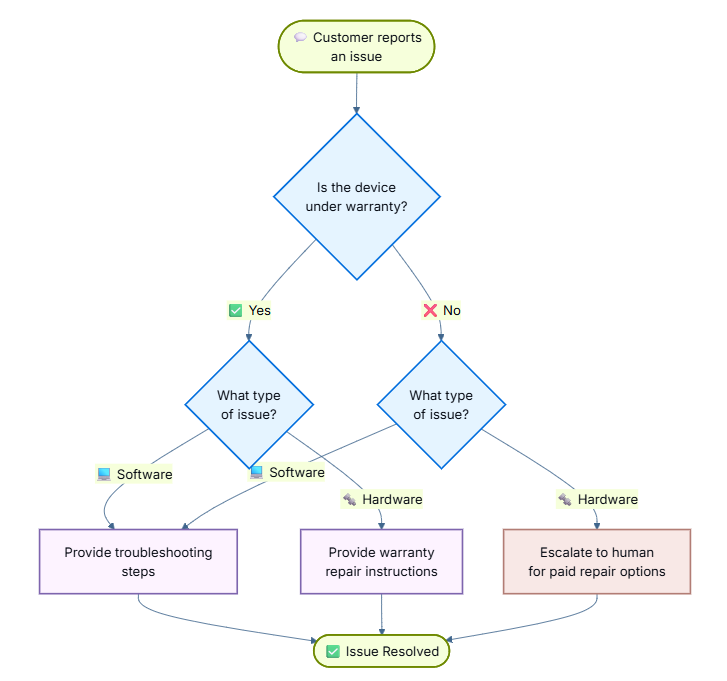

In [1]:
from dotenv import load_dotenv
import os

load_dotenv()

True

In [2]:
from langchain.chat_models import init_chat_model

model = init_chat_model(
    os.environ["OPENAI_MODEL"],
    model_provider="openai",
    use_responses_api=True,        # Responses API 사용 (Chat Completions에서는 추론 모델의 도구 호출 불가)
    reasoning={"effort": "low"},   # 추론 강도 낮춤 → 실습 속도·비용 절감
)

## 1. 상태 스키마 정의
- 현재 활성화된 단계를 추적하는 사용자 지정 상태 스키마를 정의  
- current_step필드는 상태 머신 패턴의 핵심이며, 매 턴마다 어떤 구성(프롬프트 + 도구)이 로드될지를 결정

In [4]:
from langchain.agents import AgentState
from typing_extensions import NotRequired
from typing import Literal

# 가능한 워크플로우 단계
SupportStep = Literal["warranty_collector", "issue_classifier", "resolution_specialist"]  #상태 값 제한 패턴

# 보증 상태
WarrantyStatus = Literal["in_warranty", "out_of_warranty"]

# 이슈 유형
IssueType = Literal["hardware", "software"]

class SupportState(AgentState):
    """고객 지원 워크플로우 상태"""
    current_step: NotRequired[SupportStep]  # 워크플로우 현재 단계
    warranty_status: NotRequired[WarrantyStatus]  # 보증 상태
    issue_type: NotRequired[IssueType]  # 이슈 유형

## 2. 워크플로 상태를 관리하는 도구를 생성

각 단계에서 상태를 업데이트하는 도구를 정의합니다.  
- record_warranty_status : 고객의 보증 상태를 기록하고 다음 단계(이슈 분류 단계)로 전환하는 Tool
- record_issue_type : 고객 문제 유형을 기록하고 해결 단계로 전환하는 Tool
- escalate_to_human : 고객 문제를 사람이 직접 처리하도록 에스컬레이션하는 Tool
- provide_solution : 고객 문제 해결 방안을 제공하는 Tool

In [5]:
from langchain.tools import tool, ToolRuntime
from langchain.messages import ToolMessage
from langgraph.types import Command

@tool
def record_warranty_status(
    status: Literal["in_warranty", "out_of_warranty"],
    runtime: ToolRuntime[None, SupportState],
) -> Command:
    """
    고객의 보증 상태를 기록하고 다음 단계(이슈 분류 단계)로 전환하는 Tool
    
    역할:
        1. 고객의 제품 보증 상태 저장
        2. 상태(State)에 메시지 기록
        3. 워크플로우를 다음 단계(issue_classifier)로 이동
    
    Args:
        status:
            고객 제품 보증 상태
            - "in_warranty" : 보증 기간 내
            - "out_of_warranty" : 보증 기간 외
            
        runtime:
            Tool 실행 환경 정보
            - tool_call_id : Tool 호출 추적 ID
            - 현재 Agent 실행 Context 접근 가능
            
    Returns:
        Command 객체
        → LangGraph State 업데이트 및 다음 단계 제어
    """
    
    return Command(
        update={
            # Tool 실행 결과를 메시지 히스토리에 추가
            "messages": [
                ToolMessage(
                    content=f"Warranty status recorded as: {status}",
                    # Tool 호출과 메시지를 연결하기 위한 ID
                    tool_call_id=runtime.tool_call_id,
                )
            ],
            
            # 고객 보증 상태를 State 에 저장
            "warranty_status": status,
            # 다음 워크플로우 단계 지정
            "current_step": "issue_classifier",
        }
    )


@tool
def record_issue_type(
    issue_type: Literal["hardware", "software"],
    runtime: ToolRuntime[None, SupportState],  #입력 컨텍스트는 없고(None) Agent State 타입은 SupportState를 사용
) -> Command:
    """
    고객 문제 유형을 기록하고 해결 단계로 전환하는 Tool
    
    역할:
        1. 문제 유형 저장
        2. 상태(State)에 메시지 기록
        3. 워크플로우를 해결 전문가 단계로 이동
    
    Args:
        issue_type:
            문제 유형
            - "hardware" : 하드웨어 문제
            - "software" : 소프트웨어 문제
            
        runtime:
            Tool 실행 런타임 정보
            - tool_call_id 포함
            
    Returns:
        Command 객체
        → State 업데이트 + 다음 단계 이동
    """
    
    return Command(
        update={
            # Tool 실행 결과 메시지 기록
            "messages": [
                ToolMessage(
                    content=f"Issue type recorded as: {issue_type}",
                    tool_call_id=runtime.tool_call_id,
                )
            ],
            
            # 문제 유형 상태 저장
            "issue_type": issue_type,
            # 다음 단계 설정
            "current_step": "resolution_specialist",
        }
    )


@tool
def escalate_to_human(reason: str) -> str:
    """
    고객 문제를 사람이 직접 처리하도록 에스컬레이션하는 Tool
    
    실제 시스템에서는:
        - 지원 티켓 생성
        - 담당자 알림 전송
        - CRM 시스템 등록
        등의 동작이 수행될 수 있음
    
    Args:
        reason:
            사람이 처리해야 하는 이유
            
    Returns:
        에스컬레이션 결과 메시지
    """
    
    # 실제 서비스에서는 외부 시스템 연동 로직이 들어갈 위치
    return f"Escalating to human support. Reason: {reason}"


@tool
def provide_solution(solution: str) -> str:
    """
    고객 문제 해결 방안을 제공하는 Tool
    
    역할:
        - 고객에게 해결 방법 안내
        - 자동 응답 시스템에서 해결 메시지 생성
        
    Args:
        solution:
            고객에게 전달할 해결 방안
            
    Returns:
        해결 안내 메시지
    """
    
    return f"Solution provided: {solution}"

## 3. 단계별 프롬프트 정의

각 단계마다 다른 시스템 프롬프트를 사용합니다. 
- 보증 여부 수집 단계 프롬프트
- 이슈 분류 단계 프롬프트
- 해결책 제공 단계 프롬프트

In [6]:
# 보증 수집 단계 프롬프트
WARRANTY_COLLECTOR_PROMPT = """당신은 고객 지원 에이전트입니다.

현재 단계: 보증 확인

이 단계에서 해야 할 일:
1. 고객에게 친절하게 인사하세요
2. 기기가 보증 기간 내인지 물어보세요
3. record_warranty_status 도구를 사용하여 응답을 기록하고 다음 단계로 이동하세요

대화적이고 친근하게 대화하세요. 한 번에 여러 질문을 하지 마세요."""

# 이슈 분류 단계 프롬프트
ISSUE_CLASSIFIER_PROMPT = """당신은 고객 지원 에이전트입니다.

현재 단계: 이슈 분류
고객 정보: 보증 상태는 {warranty_status}입니다

이 단계에서 해야 할 일:
1. 고객에게 문제를 설명해달라고 요청하세요
2. 하드웨어 문제(물리적 손상, 부품 고장)인지 소프트웨어 문제(앱 충돌, 성능 저하)인지 판단하세요
3. record_issue_type 도구를 사용하여 분류를 기록하고 다음 단계로 이동하세요

불명확한 경우 분류하기 전에 명확히 질문하세요."""

# 해결책 제공 단계 프롬프트
RESOLUTION_SPECIALIST_PROMPT = """당신은 고객 지원 에이전트입니다.

현재 단계: 해결책 제공
고객 정보: 보증 상태는 {warranty_status}, 이슈 유형은 {issue_type}입니다

이 단계에서 해야 할 일:
1. 소프트웨어 문제인 경우: provide_solution을 사용하여 문제 해결 단계를 제공하세요
2. 하드웨어 문제인 경우:
   - 보증 기간 내: provide_solution을 사용하여 보증 수리 프로세스를 설명하세요
   - 보증 기간 만료: escalate_to_human을 사용하여 유료 수리 옵션을 위해 인간 지원으로 에스컬레이션하세요

구체적이고 도움이 되는 해결책을 제공하세요."""

## 4. 단계별 미들웨어 생성

- 상태를 읽어 적절한 설정을 적용하는 미들웨어를 생성

- 이 미들웨어:
    - 현재 단계를 읽습니다 . current_step상태에서 값을 가져옵니다(기본값은 "warranty_collector").
    - 구성 조회 : 에서 일치하는 항목을 찾습니다 STEP_CONFIG.
    - 종속성 유효성 검사 : 필수 상태 필드가 존재하는지 확인합니다.
    - 프롬프트 형식 지정 : 프롬프트 템플릿에 상태 값을 삽입합니다.
    - 구성 적용 : 시스템 메시지 및 사용 가능한 도구를 재정의합니다.

- request.override() 방법을 사용하면 별도의 에이전트 인스턴스를 생성하지 않고도 상태에 따라 에이전트의 동작을 동적으로 변경할 수 있습니다.

In [7]:
from langchain.agents.middleware import wrap_model_call, ModelRequest, ModelResponse
from typing import Callable

STEP_CONFIG = {
    "warranty_collector": {
        "prompt": WARRANTY_COLLECTOR_PROMPT,     # 해당 단계에서 사용할 시스템 프롬프트
        "tools": [record_warranty_status],       # 사용 가능한 Tool 목록
        "requires": [],                          # 진입 조건 (없음)
    },

    "issue_classifier": {
        "prompt": ISSUE_CLASSIFIER_PROMPT,
        "tools": [record_issue_type],
        "requires": ["warranty_status"],         # 진입 조건 - warranty_status 가 먼저 기록되어야 진입 가능
    },

    "resolution_specialist": {
        "prompt": RESOLUTION_SPECIALIST_PROMPT,
        "tools": [provide_solution, escalate_to_human],
        "requires": ["warranty_status", "issue_type"],  # 진입 조건 - 두 상태 모두 필요
    },
}


# ------------------------------------------------------------
# Model Call Middleware 정의
# ------------------------------------------------------------
# wrap_model_call → LLM 호출 직전에 개입하여 시스템 프롬프트 변경,
# Tool 목록 변경, 요청 파라미터 수정 등을 수행할 수 있는 미들웨어 데코레이터

@wrap_model_call
def apply_step_config(
    request: ModelRequest,
    handler: Callable[[ModelRequest], ModelResponse],
) -> ModelResponse:
    """
    현재 Agent 상태에 따라, 시스템 프롬프트, 사용 가능한 Tool 목록
    을 동적으로 적용하는 Middleware

    실행 흐름:
        1. 현재 workflow 단계 확인
        2. 단계 진입 조건 검증
        3. 단계별 시스템 프롬프트 생성
        4. Tool 목록 설정
        5. 수정된 요청을 LLM에 전달
    """

    # state 에 current_step 값이 없으면 기본 단계는 warranty_collector
    current_step = request.state.get("current_step", "warranty_collector")

    # 해당 단계 설정 정보 조회
    stage_config = STEP_CONFIG[current_step]

    for key in stage_config["requires"]:          # 이 단계의 필수 조건 목록을 하나씩 처리
        if request.state.get(key) is None:        # 상태에 그 값이 아직 없으면 실행을 중단시키고 에러 발생
            raise ValueError(...)                  

    # 시스템 프롬프트 동적 생성
    format_kw = {
        "warranty_status": request.state.get("warranty_status", "알 수 없음"),
        "issue_type": request.state.get("issue_type", "알 수 없음"),
    }

    # 단계별 프롬프트 템플릿에 상태 값 삽입
    system_prompt = stage_config["prompt"].format(**format_kw)

    # ------------------------------------------------------------
    # ModelRequest 수정
    # ------------------------------------------------------------
    # override(): 기존 요청 객체를 복사하면서 특정 필드만 변경하는 불변 객체 패턴

    request = request.override(
        system_prompt=system_prompt,   # 단계별 시스템 프롬프트 적용
        tools=stage_config["tools"],   # 단계별 Tool 허용 목록 적용
    )

    # 수정된 요청을 실제 LLM 호출 핸들러로 전달
    return handler(request)

## 5. 에이전트 생성

state_schema와 apply_step_config 미들웨어로 단계별 프롬프트·도구를 적용합니다.

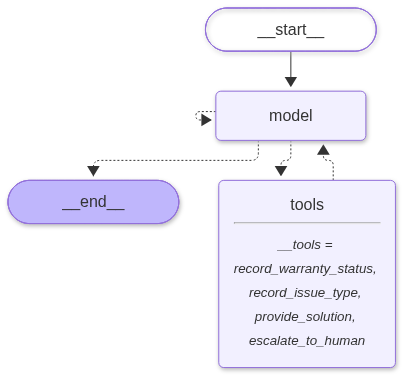

In [8]:
from langchain.agents import create_agent
from langgraph.checkpoint.memory import InMemorySaver

# Agent 에서 사용할 모든 Tool 목록 정의
all_tools = [
    record_warranty_status,   # 보증 상태 기록 Tool
    record_issue_type,        # 문제 유형 기록 Tool
    provide_solution,         # 해결 방안 제공 Tool
    escalate_to_human,        # 사람 상담원 연결 Tool
]

# Agent 생성
agent = create_agent(
    model,
    tools=all_tools,
    state_schema=SupportState,  # Agent 실행 중 상태를 구조적으로 관리하기 위한 타입 정의
    middleware=[apply_step_config],  #현재 단계 확인, 시스템 프롬프트 변경, Tool 사용 제한
    checkpointer=InMemorySaver(),
)

agent

## 7. 멀티 턴 대화 실행

여러 턴에 걸쳐 상태 전환을 확인합니다.

In [9]:
from langchain_core.messages import HumanMessage
import uuid  # 고유 ID 생성을 위한 모듈

thread_id = str(uuid.uuid4())

config = {"configurable": {"thread_id": thread_id}}

print("=" * 80)
print("턴 1: 보증 확인 - warranty_collector 단계에서 시작")
print("=" * 80)

# Agent 실행
result = agent.invoke(
    {
        "messages": [
            HumanMessage(
                content="안녕하세요, 제 휴대폰 화면이 깨졌어요."
            )
        ]
    },
    config=config
)

# Agent 응답 메시지 출력
msg = result["messages"][-1]
print(msg.text)

# 현재 Workflow 단계 출력
# current_step → Agent 상태(State)에 저장된 현재 단계

print(f"\n현재 단계: {result.get('current_step', 'N/A')}")

턴 1: 보증 확인 - warranty_collector 단계에서 시작
안녕하세요! 휴대폰 화면이 깨져서 많이 불편하시겠어요. 휴대폰이 아직 보증 기간 내인가요?

현재 단계: N/A


### 턴 2: 보증 상태 응답

In [10]:
print("\n" + "=" * 80)
print("턴 2: 보증 상태 응답")
print("=" * 80)

result = agent.invoke(
    {"messages": [HumanMessage(content="네, 아직 보증 기간 내입니다.")]},
    config=config
)

msg = result["messages"][-1]
print(msg.text)

print(f"\n현재 단계: {result.get('current_step', 'N/A')}")
print(f"보증 상태: {result.get('warranty_status', 'N/A')}")


턴 2: 보증 상태 응답
보증 기간 내이므로 제조사 또는 공식 서비스센터에 수리 접수를 해 주세요. 다만 화면 파손은 낙하나 충격으로 인한 손상이라면 일반 보증에서 제외되어 수리비가 발생할 수 있으니, 접수할 때 보증 적용 여부와 비용을 먼저 확인하세요.

방문 전에는 가능하면 데이터를 백업하고, 모델명과 구매 증빙을 준비해 주세요. 깨진 유리에 손을 다치지 않도록 화면을 만지지 마시고, 화면이 들뜨거나 기기가 뜨거워지는 등 이상이 있으면 전원을 끄고 사용을 중단한 뒤 서비스센터에 문의하세요.

현재 단계: resolution_specialist
보증 상태: in_warranty


### 턴 3: 이슈 설명

In [11]:
print("\n" + "=" * 80)
print("턴 3: 이슈 설명")
print("=" * 80)

result = agent.invoke(
    {"messages": [HumanMessage(content="화면이 물리적으로 깨졌어요. 떨어뜨려서 그런 것 같아요.")]},
    config=config
)

msg = result["messages"][-1]
print(msg.text)

print(f"\n현재 단계: {result.get('current_step', 'N/A')}")
print(f"이슈 유형: {result.get('issue_type', 'N/A')}")


턴 3: 이슈 설명
낙하로 인한 물리적 파손은 보증 기간 중이어도 일반 보증에서 제외되어 **유상 수리**가 될 가능성이 큽니다. 제조사 공식 서비스센터에 파손 상황을 알리고 점검과 견적을 요청해 주세요. 수리를 승인하기 전에 비용, 수리 기간, 데이터 초기화 여부를 확인하고 가능하면 데이터를 백업해 두세요. 깨진 유리를 만지지 마시고, 화면이 들뜨거나 기기가 뜨거워지면 전원을 끄고 충전하지 않은 채 서비스센터에 문의하세요.

현재 단계: resolution_specialist
이슈 유형: hardware


### 턴 4: 해결책 제공

In [12]:
print("\n" + "=" * 80)
print("턴 4: 해결책 제공")
print("=" * 80)

result = agent.invoke(
    {"messages": [HumanMessage(content="어떻게 해야 하나요?")]},
    config=config
)

msg = result["messages"][-1]
print(msg.text)

print(f"\n현재 단계: {result.get('current_step', 'N/A')}")


턴 4: 해결책 제공
다음 순서로 진행해 주세요.

1. **깨진 화면을 누르거나 유리 조각을 만지지 마세요.** 발열이나 화면 들뜸이 있으면 전원을 끄고 충전하지 마세요.
2. 기기가 안전하게 작동하면 중요한 데이터를 백업하세요.
3. 제조사 공식 서비스센터에 연락하거나 방문해 **“보증 기간 중 낙하로 화면이 깨졌다”**고 설명하고 점검과 수리 견적을 요청하세요. 낙하 파손은 보증에서 제외되어 유상일 수 있습니다.
4. 수리 승인 전에 총 비용, 수리 기간, 데이터 초기화 여부를 확인하세요. 모델명과 구매 증빙도 준비해 두시면 좋습니다.

현재 단계: resolution_specialist


## 8. 보증 기간 만료 시나리오

보증 기간이 만료된 경우의 워크플로우를 테스트합니다.

In [ ]:
# 새로운 스레드로 보증 기간 만료 시나리오
thread_id2 = str(uuid.uuid4())
config2 = {"configurable": {"thread_id": thread_id2}}

print("=" * 80)
print("보증 기간 만료 시나리오:")
print("=" * 80)

# 턴 1
result = agent.invoke(
    {"messages": [HumanMessage(content="제품에 문제가 있어요.")]},
    config=config2
)

# 턴 2: 보증 기간 만료
result = agent.invoke(
    {"messages": [HumanMessage(content="아니요, 보증 기간이 지났어요.")]},
    config=config2
)

print(f"보증 상태: {result.get('warranty_status', 'N/A')}")

# 턴 3: 하드웨어 문제
result = agent.invoke(
    {"messages": [HumanMessage(content="하드웨어 문제예요. 배터리가 부풀어 올랐어요.")]},
    config=config2
)

print(f"이슈 유형: {result.get('issue_type', 'N/A')}")

# 턴 4: 해결책 (에스컬레이션 예상)
result = agent.invoke(
    {"messages": [HumanMessage(content="어떻게 해야 하나요?")]},
    config=config2
)

msg = result["messages"][-1]
print(msg.text)

보증 기간 만료 시나리오:
보증 상태: out_of_warranty
